# **Tarea 1 – Analítica de Datos (MACI 2026)**

**Alumno:** Keyden Urbina

**Mercado de celulares en Chile (solotodo.cl) y modelo de rango de precios**

**Data Wrangling**

**Entrada:** `data/output/data_raw.csv` (última extracción del notebook 01) → **Salida:** `data/processed/data_processed.csv`

| Paso | Qué hace |
|---|---|
| 1 | Librerías y rutas |
| 2 | Diagnóstico de calidad del RAW: faltantes y repetidos, por columna y por fila |
| 3 | Limpieza: ofertas con plan fuera, texto → números, condición y publicaciones repetidas |
| 4 | Faltantes que quedan y guardado (la imputación se hace en el notebook 04) |


Las cifras de las interpretaciones corresponden a la extracción del **08-11-2026 11:55** (web scraping del HTML, columna `fecha_extraccion`).

### Decisiones en la creación del dataset (resumen)

| Decisión | Qué se hizo | Justificación | Dónde |
|---|---|---|---|
| Alcance | Catálogo completo: 13 páginas, 242 celulares | Evita el sesgo hacia los modelos populares de las primeras páginas | 01 |
| Páginas de modelo | Se usa la variante **que la página muestra al hacer clic** (`?product=` del enlace) | La primera de la lista interna difiere en 9 de 13 páginas (en 6 iPhone es la de 1 TB) | 01 |
| Ofertas con plan de compañía | Se **guardan** en el RAW (`tipo_oferta`) y se **excluyen** en la limpieza | El RAW va sin limpiar. Su precio es un arriendo (ej. \$9.990 + cuota mensual), no el precio del equipo | 01–02 |
| Celulares sin oferta liberada | **Se conservan** con su ficha y precio vacío (`disponibilidad`: "Solo con plan" o "Sin ofertas") | No sirven para comparar precios ni como etiqueta del modelo, pero sí para contar los modelos del mercado (pregunta c). Cada pregunta filtra lo que necesita | 02–04 |
| Tiendas | Se usan **todas**; ninguna se omite | El enunciado pide los precios en las distintas tiendas, y la pregunta b compara tiendas | 01 |
| ¿Precio más bajo o más alto? | Ninguno: se conserva **un precio por tienda** | Permite comparar tiendas (b) y medir la dispersión de precios (a) | 01–02 |
| Precio oferta | Precio tarjeta; si hay **cupón**, se descuenta | El enunciado define precio oferta como "tarjeta o cupón" | 02 |
| Precio de un modelo (para el clasificador) | **Mediana** de sus tiendas | Robusta a una tienda con un precio extremo | 04 |
| Publicaciones repetidas | Se deja **una** cuando dos ofertas coinciden en celular, tienda, condición y precios | Tienen `id_oferta` distinto: no son errores de la extracción, sino publicaciones distintas (otro color, con o sin regalo). Contarlas dos veces duplicaría el peso de ese precio en los promedios | 02 |
| Mismo celular y tienda, otro precio | **Conservados** | Son ofertas distintas (vendedores de marketplace, unidades usadas en distinto estado) | 02 |
| Condición | `condicion` con 3 categorías (nuevo, reacondicionado, usado) y `es_nuevo` (1/0) | Usado y reacondicionado no son lo mismo. `es_nuevo` filtra las preguntas a y b y el modelo; en c cuentan todos los modelos | 02–04 |
| "N/A" en características | **Quedan vacíos** en `data_processed`. Se imputan en el 04 con la mediana de la marca (o la general), aprendida **solo con entrenamiento** | Calcular la mediana antes de dividir usaría información de validación y test (fuga de datos) | 04 |
| Marca faltante | 1ª palabra del nombre | El celular sin ofertas no trae la marca en el HTML; en los otros 241 la marca coincide siempre con la 1ª palabra | 02 |
| Cámaras con varios sensores | **Suma** de los MP | Representa la capacidad total del sistema de cámaras | 02 |

### Paso 1: Importar las librerías y crear las rutas

In [1]:
# Librerías que usa este notebook

import numpy as np                 # cálculos numéricos (np.where para descontar cupones)
import pandas as pd                # tablas: leer, limpiar y guardar CSV
from pathlib import Path           # rutas de carpetas (OUT y PROC)
import matplotlib.pyplot as plt    # graficar

In [2]:
# Carpeta de salida: busca "data/output" subiendo desde donde se ejecuta (sirve desde notebooks/ o desde la raíz del proyecto)

OUT = next((p / "data" / "output" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "output").is_dir()), Path("data/output"))
OUT.mkdir(parents=True, exist_ok=True)                # si no existe, la crea
PROC = OUT.parent / "processed"                       # data/processed: misma ruta, carpeta hermana de output
PROC.mkdir(exist_ok=True)                             # si no existe, la crea
print("RAW →", OUT.resolve(), "\nProcesados →", PROC.resolve())

RAW → /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/output 
Procesados → /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/processed


### Paso 2: Diagnóstico de calidad del RAW (antes de limpiar)

Se cuentan los faltantes por columna y por fila, y los repetidos. Hay **tres tipos de faltante**, y cada uno se trata distinto:

1. **Estructural** (`cupon_tipo`, `cupon_monto`): vacío significa "la tienda no tiene cupón". No es un dato perdido: se toma como descuento 0.

2. **Sin oferta** (tienda, `id_oferta`, `url_oferta`, precios, condición, tipo de oferta y marca vacíos): el celular está en el catálogo, pero ninguna tienda lo vende. Se conserva con su ficha y precio vacío.

3. **No informado** ("N/A" en peso, batería, cámara frontal…): el sitio no publica el dato. Queda vacío en `data_processed`.

#### 2.1 Faltantes y repetidos por columna

1104 filas × 35 columnas = 38640 celdas | faltantes: 2233 (5.8%)


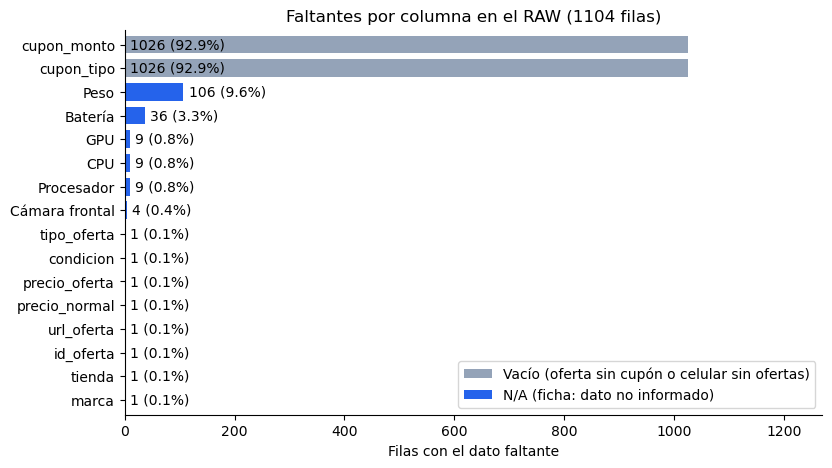

,vacíos,N/A,NaN total,% NaN,únicos,repetidos
nombre,0,0,0,0.0,242,862
marca,1,0,1,0.1,16,1087
id,0,0,0,0.0,242,862
Pantalla,0,0,0,0.0,138,966
Memoria interna,0,0,0,0.0,8,1096
RAM,0,0,0,0.0,9,1095
Cámara principal,0,0,0,0.0,93,1011
Cámara frontal,0,4,4,0.4,22,1078
Batería,0,36,36,3.3,78,990
Sistema operativo,0,0,0,0.0,22,1082


In [3]:
# Diagnóstico de calidad del RAW, antes de limpiar

df  = pd.read_csv(OUT / "data_raw.csv")                                    # como lo ve pandas: "" y "N/A" pasan a NaN
txt = pd.read_csv(OUT / "data_raw.csv", dtype=str, keep_default_na=False)  # como texto puro: deja ver "" y "N/A" por separado

calidad = pd.DataFrame({
    "vacíos":    txt.eq("").sum(),                 # celda sin nada (ej. tienda sin cupón, modelo sin precio liberado)
    "N/A":       txt.eq("N/A").sum(),              # el sitio publica "N/A": dato no informado
    "NaN total": df.isna().sum(),                  # lo que pandas trata como faltante (= vacíos + N/A)
    "% NaN":     (df.isna().mean() * 100).round(1),
    "únicos":    df.nunique(),                     # valores distintos en la columna
    "repetidos": df.count() - df.nunique(),        # valores no vacíos que ya habían aparecido en la columna
})
print(f"{df.shape[0]} filas × {df.shape[1]} columnas = {df.size} celdas | faltantes: {df.isna().sum().sum()} ({df.isna().sum().sum() / df.size:.1%})")

# Gráfico: faltantes por columna, separando vacíos (gris) y "N/A" (azul)
g = calidad[calidad["NaN total"] > 0].sort_values("NaN total")            # solo columnas con faltantes, de menor a mayor
ax = g[["vacíos", "N/A"]].plot.barh(stacked=True, color=["#94a3b8", "#2563eb"], figsize=(9, 5), width=0.75)   # barras apiladas
ax.bar_label(ax.containers[-1], labels=[f"{n} ({p}%)" for n, p in zip(g["NaN total"], g["% NaN"])], padding=4)  # total y % al final
ax.set_xlim(right=len(df) * 1.15)                                         # eje hasta el total de filas, con espacio para etiquetas
ax.set(title=f"Faltantes por columna en el RAW ({len(df)} filas)", xlabel="Filas con el dato faltante", ylabel="")
ax.legend(["Vacío (oferta sin cupón o celular sin ofertas)", "N/A (ficha: dato no informado)"], loc="lower right")
ax.spines[["top", "right"]].set_visible(False)                            # quita bordes que no aportan
plt.show()

calidad                                                                   # la tabla se muestra debajo del gráfico

**Interpretación:**

- El RAW tiene **1.104 filas × 35 columnas = 38.640 celdas**, con **2.233 faltantes (5,8 %)**.

- **El 92 % de los faltantes (2.052 celdas) es estructural:** son los cupones vacíos de las 1.026 filas (92,9 %) cuya tienda no ofrece cupón. No falta información.

- **8 celdas son de la única fila sin ofertas** (Vivo Y70 FE): marca, tienda, `id_oferta`, `url_oferta`, los dos precios, condición y tipo de oferta. El celular está en el catálogo, pero ninguna tienda lo vende.

- **173 celdas dicen "N/A"** porque el sitio no informa el dato: peso 106 (9,6 %), batería 36 (3,3 %), procesador, CPU y GPU 9 cada una (0,8 %) y cámara frontal 4 (0,4 %). De estas, solo peso, batería y cámara frontal están entre las columnas a limpiar.

- Los **vacíos** y los **"N/A"** nunca coinciden en una misma columna: los vacíos están en los datos de las ofertas (precios y cupones) y los "N/A", en la ficha técnica. Son dos orígenes distintos dentro del HTML.

- Los **repetidos por columna son esperables**: hay 242 celulares en 1.104 filas, o sea, cada celular aparece en ~4,6 ofertas y sus características se repiten. En cambio, `id_oferta` tiene **1.103 valores distintos en 1.103 ofertas**: cada fila es una publicación distinta. `Bluetooth` y `fecha_extraccion` tienen un solo valor: todos los equipos tienen Bluetooth y todo viene de una sola extracción.

#### 2.2 Faltantes por fila y repetidos

Filas completas: 66 | con al menos 1 faltante: 1038
Ofertas repetidas por la extracción (mismo id_oferta): 0
Filas iguales salvo id y URL: 37 sobrantes, en 34 grupos; 32 grupos tienen URLs distintas
Mismo celular en la misma tienda: 84


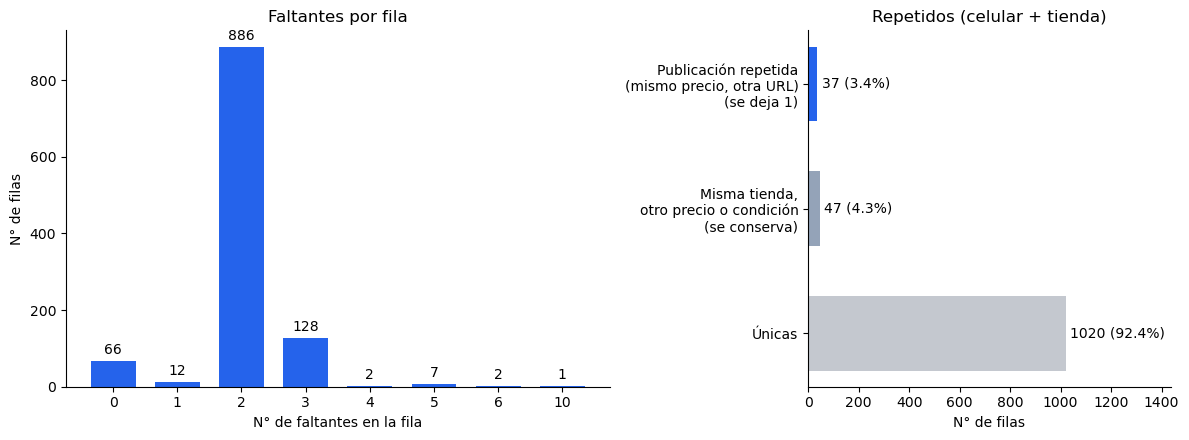

,n° de filas
faltantes en la fila,
0,66
1,12
2,886
3,128
4,2
5,7
6,2
10,1


In [4]:
por_fila = df.isna().sum(axis=1)                                          # n° de faltantes en cada fila
rasgos = df.columns.drop(["id_oferta", "url_oferta"])                     # todo menos la trazabilidad de la oferta
extraccion = df.id_oferta.dropna().duplicated().sum()                     # misma oferta (mismo id) repetida por la extracción
iguales = df.duplicated(rasgos).sum()                                     # filas iguales en todo salvo id y URL de la oferta
clave = df.duplicated(["nombre", "tienda"]).sum()                         # mismo celular en la misma tienda (incluye los anteriores)
grupos = df[df.duplicated(rasgos, keep=False)].groupby(list(rasgos), dropna=False).url_oferta.nunique()   # URLs distintas por grupo
print(f"Filas completas: {(por_fila == 0).sum()} | con al menos 1 faltante: {(por_fila > 0).sum()}")
print(f"Ofertas repetidas por la extracción (mismo id_oferta): {extraccion}")
print(f"Filas iguales salvo id y URL: {iguales} sobrantes, en {len(grupos)} grupos; {(grupos > 1).sum()} grupos tienen URLs distintas")
print(f"Mismo celular en la misma tienda: {clave}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [3, 2]})   # 2 gráficos lado a lado

# Gráfico 1: cuántas filas tienen 0, 1, 2… faltantes
dist = por_fila.value_counts().sort_index()                               # n° de filas por cantidad de faltantes
a1.bar(dist.index.astype(str), dist, color="#2563eb", width=0.7)
a1.bar_label(a1.containers[0], padding=3)                                 # cantidad sobre cada barra
a1.set(title="Faltantes por fila", xlabel="N° de faltantes en la fila", ylabel="N° de filas")

# Gráfico 2: filas únicas vs. repetidas
dup = pd.Series({"Únicas": len(df) - clave,
                 "Misma tienda,\notro precio o condición\n(se conserva)": clave - iguales,
                 "Publicación repetida\n(mismo precio, otra URL)\n(se deja 1)": iguales})
a2.barh(dup.index, dup, color=["#c4c8cf", "#94a3b8", "#2563eb"], height=0.6)
a2.bar_label(a2.containers[0], labels=[f"{v} ({v/len(df):.1%})" for v in dup], padding=3)   # cantidad y % del total
a2.set_xlim(right=len(df) * 1.3)                                          # espacio para las etiquetas
a2.set(title="Repetidos (celular + tienda)", xlabel="N° de filas")

for a in (a1, a2): a.spines[["top", "right"]].set_visible(False)          # quita bordes que no aportan
plt.tight_layout()                                                        # evita que los textos se encimen
plt.show()

dist.rename_axis("faltantes en la fila").to_frame("n° de filas")          # la tabla se muestra debajo del gráfico

**Interpretación:**
- Solo **66 filas (6 %) están completas**, pero esa cifra exagera el problema: **886 filas tienen exactamente 2 faltantes**, que son las dos columnas de cupón (estructurales). Las 128 filas con 3 suman a los cupones un "N/A" de la ficha: el peso (99) o la batería (29).

- La fila con **10 faltantes** es el Vivo Y70 FE, el único celular sin ninguna oferta.

- **La extracción no repitió ninguna oferta:** cada `id_oferta` aparece una sola vez.

- **37 filas son iguales a otra en todo salvo el id y la URL**, en 34 grupos. En 32 de esos grupos las URLs son distintas: son **publicaciones distintas con el mismo precio**. Los otros 2 comparten URL, pero tienen id distinto: el Poco F8 Pro, publicado 4 veces por Xiaomi Chile, y el ZTE Nubia Neo 5 GT, 2 veces en WOM.

- **84 filas repiten celular + tienda:** 37 son esas publicaciones repetidas y 47 son ofertas con otro precio o condición (vendedores de marketplace, unidades usadas en distinto estado). Esas 47 se conservan.

#### 2.3 Ejemplos de publicaciones repetidas

In [5]:
# Ejemplos de publicaciones repetidas: iguales en todo salvo id y URL (keep=False muestra todas las copias)
df[df.duplicated(rasgos, keep=False)].sort_values(["nombre", "tienda"])[["nombre", "tienda", "precio_oferta", "condicion", "url_oferta"]].head(10)

,nombre,tienda,precio_oferta,condicion,url_oferta
168,Apple iPhone 16e (128 GB / White) [MD1R4BE/A],ABC,499990.0,https://schema.org/NewCondition,https://www.abc.cl/apple-iphone-16e-128gb-blan...
169,Apple iPhone 16e (128 GB / White) [MD1R4BE/A],ABC,499990.0,https://schema.org/NewCondition,https://www.abc.cl/apple-iphone-16e-128gb-negr...
592,Honor 600 (512 GB / 8 GB / Black) [5109CHBV-B],CTMAN,639170.0,https://schema.org/NewCondition,https://www.ctman.cl/products/honor-600-smartp...
593,Honor 600 (512 GB / 8 GB / Black) [5109CHBV-B],CTMAN,639170.0,https://schema.org/NewCondition,https://www.ctman.cl/products/honor-600-smartp...
585,Honor 600 (512 GB / 8 GB / Black) [5109CHBV-B],Hites,577990.0,https://schema.org/NewCondition,https://www.hites.com/smartphone-honor-600-5g-...
586,Honor 600 (512 GB / 8 GB / Black) [5109CHBV-B],Hites,577990.0,https://schema.org/NewCondition,https://www.hites.com/smartphone-honor-600-5g-...
598,Honor 600 (512 GB / 8 GB / Black) [5109CHBV-B],NotebookStore,652040.0,https://schema.org/NewCondition,https://notebookstore.cl/honor-600-smartphone-...
599,Honor 600 (512 GB / 8 GB / Black) [5109CHBV-B],NotebookStore,652040.0,https://schema.org/NewCondition,https://notebookstore.cl/smartphone-honor-600-...
596,Honor 600 (512 GB / 8 GB / Black) [5109CHBV-B],Paris,649990.0,https://schema.org/NewCondition,https://www.paris.cl/smartphone-honor-600-5g-5...
597,Honor 600 (512 GB / 8 GB / Black) [5109CHBV-B],Paris,649990.0,https://schema.org/NewCondition,https://www.paris.cl/smartphone-honor-600-5g-5...


**Interpretación:** 

Las copias coinciden en celular, tienda, precio y condición, pero cada una es una **publicación distinta**, con su propio `id_oferta` y casi siempre su propia URL. Hay dos casos típicos:

- **El mismo equipo en otro color:** ABC publica el iPhone 16e blanco y el negro dentro de la misma variante, al mismo precio.

- **Con y sin regalo:** Hites y Paris publican el Honor 600 con audífonos de regalo y sin ellos, al mismo precio.

Paris (5), Hites, Ripley y ABC (4 cada una) son las tiendas con más publicaciones repetidas. Como el precio es idéntico, contarlas dos veces duplicaría el peso de ese precio en los promedios por tienda y por marca. Por eso se deja **una por grupo**. No es un error de la extracción: el notebook 01 confirma 1.103 `id_oferta` distintos.

### Paso 3: Limpieza: texto → números

| Columna | Regla de limpieza |
|---|---|
| Precio normal | Precio "normal" o "con todo medio de pago" (ya numérico en la fuente). |
| Precio oferta | Precio tarjeta; si hay cupón se descuenta (% o monto fijo), igual que en la ficha. |
| Memoria / RAM (GB) | Número × unidad: MB ÷ 1024, TB × 1024. |
| Pantalla (pulgadas) | Número pegado a `"`; acepta coma decimal (`8,1"` → 8.1). |
| Cámara principal / frontal (MP) | Suma de todos los números seguidos de "MP" (ignora el "3D" del sensor TOF; corrige "200,0" → 200.0). |
| Batería (mAh), Peso (g) | Primer número del texto. |
| NFC | Sí = 1, No = 0. |
| Condición | `condicion`: nuevo, reacondicionado o usado (desde el valor de schema.org). `es_nuevo` = 1 si es nuevo. |
| Marca | Si falta (celular sin ofertas), se toma la 1ª palabra del nombre. |

Además se eliminan las **ofertas con plan** (`tipo_oferta` distinto de "Liberado") y las **publicaciones repetidas** (Paso 2). Los celulares sin oferta liberada **se conservan** con una fila: su ficha y precio vacío.

Ofertas con plan eliminadas: 74 | celulares sin oferta liberada que se conservan: 10
Publicaciones repetidas eliminadas: 33
NaN en la tabla limpia: {'tienda': 10, 'id_oferta': 10, 'condicion': 10, 'es_nuevo': 10, 'precio_normal': 10, 'precio_oferta': 10, 'camara_frontal_mp': 4, 'bateria_mah': 33, 'peso_g': 88}


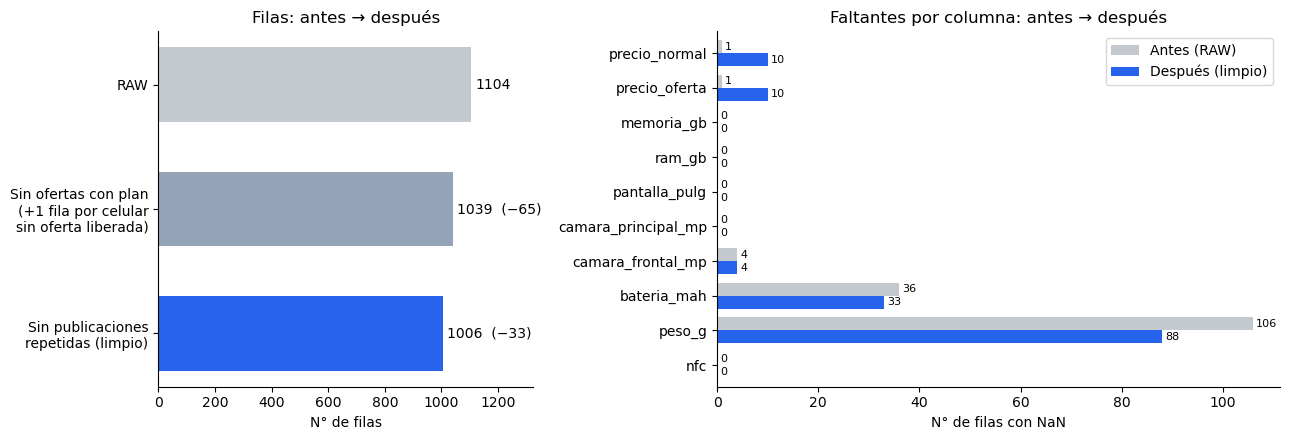

,"antes (RAW, texto)","después (limpio, número)"
Xiaomi 15 Ultra (White),,
precio_normal,944990.0,944990.0
precio_oferta,944990.0,897740.0
memoria_gb,512 GB,512.0
ram_gb,16 GB,16.0
pantalla_pulg,"AMOLED 6.7"" táctil (3200x1440) / 120 Hz",6.7
camara_principal_mp,Estándar 50.0 MP + Teleobjetivo Periscopio (Zo...,350.0
camara_frontal_mp,Estándar 32.0 MP,32.0
bateria_mah,5410 mAh,5410.0
peso_g,226 g.,226.0


In [6]:
raw = pd.read_csv(OUT / "data_raw.csv")               # vuelve a leer el RAW tal cual (el diagnóstico no lo modifica)

# 1) Ofertas con plan fuera, celulares dentro: el precio con plan es un arriendo, no el del equipo,
#    pero el celular existe en el mercado. Los que no tienen ninguna oferta liberada quedan con 1 fila: su ficha y precio vacío.

lib = raw.tipo_oferta.eq("Liberado")                                       # ofertas de equipo liberado
otros = raw[~raw.id.isin(raw.id[lib])].drop_duplicates("id").copy()        # 1 fila por celular SIN oferta liberada
otros["disponibilidad"] = np.where(otros.tipo_oferta.notna(), "Solo con plan", "Sin ofertas")
otros[["tienda", "id_oferta", "precio_normal", "precio_oferta", "condicion", "cupon_tipo", "cupon_monto"]] = np.nan   # sin precio de equipo
df = pd.concat([raw[lib].assign(disponibilidad="Liberado"), otros])
print(f"Ofertas con plan eliminadas: {(raw.tipo_oferta.notna() & ~lib).sum()} | celulares sin oferta liberada que se conservan: {len(otros)}")

# Herramientas de limpieza (cada una devuelve una columna numérica; si el texto es "N/A" queda NaN)

num = lambda col, patron=r"([\d.]+)": pd.to_numeric(df[col].str.replace(",", ".").str.extract(patron, expand=False), errors="coerce")  # 1er número del texto ("8,1" → 8.1)
gb  = lambda col: num(col) * df[col].str.extract(r"(MB|GB|TB)", expand=False).map({"MB": 1/1024, "GB": 1, "TB": 1024})  # todo a GB
mp  = lambda col: df[col].str.replace(",", ".").str.extractall(r"([\d.]+) MP")[0].astype(float).groupby(level=0).sum()  # suma de "X MP"

# Precio oferta = precio tarjeta; si la tienda tiene cupón, se le descuenta (así lo muestra la ficha: "$239.990 → $227.991")

desc = np.where(df.cupon_tipo.eq("Percentage"), df.precio_oferta * df.cupon_monto / 100, df.cupon_monto.fillna(0))
estado = df.condicion.str.replace("https://schema.org/", "").map({"NewCondition": "nuevo", "RefurbishedCondition": "reacondicionado", "UsedCondition": "usado"})

clean = pd.DataFrame({
    "nombre": df.nombre,                                                   # identificador único
    "marca": df.marca.str.strip().fillna(df.nombre.str.split().str[0]),   # sin ofertas no hay marca en el HTML: se toma la 1ª palabra del nombre (en los otros 241 celulares, coincide siempre)
    "disponibilidad": df.disponibilidad,                                   # Liberado / Solo con plan / Sin ofertas
    "tienda": df.tienda,
    "id_oferta": df.id_oferta.astype("Int64"),                             # trazabilidad: publicación de origen
    "condicion": estado,                                                   # nuevo / reacondicionado / usado
    "es_nuevo": estado.map({"nuevo": 1, "reacondicionado": 0, "usado": 0}),   # filtro de las preguntas a, b y del modelo
    "precio_normal": df.precio_normal,
    "precio_oferta": (df.precio_oferta - desc).round(),
    "memoria_gb": gb("Memoria interna"),          # "1 TB" → 1024
    "ram_gb": gb("RAM"),                           # "128 MB" → 0.125
    "pantalla_pulg": num("Pantalla", r'([\d.]+)"'),   # el número pegado a las comillas: '... 6.1" táctil' → 6.1
    "camara_principal_mp": mp("Cámara principal"),    # "Estándar 48.0 MP + Gran angular 12.0 MP" → 60.0
    "camara_frontal_mp": mp("Cámara frontal"),
    "bateria_mah": num("Batería"),
    "peso_g": num("Peso"),                         # "218 g." → 218
    "nfc": df.NFC.map({"Sí": 1, "No": 0}),          # 1 = Sí, 0 = No
})
assert clean.condicion.notna().sum() == df.condicion.notna().sum(), "hay una condición que no es nuevo, reacondicionado ni usado"

# 2) Publicaciones repetidas: iguales en todo salvo id_oferta (otra URL, mismo precio). Se deja 1 para no duplicar su peso

rasgos = clean.columns.drop("id_oferta")
n_con_plan_fuera = len(clean)                     # filas tras quitar las ofertas con plan (para el gráfico)
print("Publicaciones repetidas eliminadas:", clean.duplicated(rasgos).sum())
clean = clean.drop_duplicates(rasgos)
print("NaN en la tabla limpia:", clean.isna().sum()[lambda x: x > 0].to_dict())

# ---------- Antes vs. después ----------
origen = {"precio_normal": "precio_normal", "precio_oferta": "precio_oferta", "memoria_gb": "Memoria interna",
          "ram_gb": "RAM", "pantalla_pulg": "Pantalla", "camara_principal_mp": "Cámara principal",
          "camara_frontal_mp": "Cámara frontal", "bateria_mah": "Batería", "peso_g": "Peso", "nfc": "NFC"}   # columna limpia → columna RAW

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 3]})

# Gráfico 1: filas en cada etapa
etapas = pd.Series({"RAW": len(raw), "Sin ofertas con plan\n(+1 fila por celular\nsin oferta liberada)": n_con_plan_fuera, "Sin publicaciones\nrepetidas (limpio)": len(clean)})
a1.barh(etapas.index[::-1], etapas[::-1], color=["#2563eb", "#94a3b8", "#c4c8cf"], height=0.6)   # de arriba (RAW) hacia abajo
quitadas = -etapas.diff().fillna(0).astype(int)                       # filas eliminadas en cada etapa
a1.bar_label(a1.containers[0], labels=[f"{v}" + (f"  (−{q})" if q else "") for v, q in zip(etapas[::-1], quitadas[::-1])], padding=3)
a1.set_xlim(right=len(raw) * 1.2); a1.set(title="Filas: antes → después", xlabel="N° de filas")

# Gráfico 2: faltantes por columna, en el RAW vs. en la tabla limpia (lo que queda por imputar)
nan = pd.DataFrame({"Antes (RAW)": raw[list(origen.values())].isna().sum().values,
                    "Después (limpio)": clean[list(origen)].isna().sum().values}, index=list(origen))
nan.plot.barh(ax=a2, color=["#c4c8cf", "#2563eb"], width=0.75)
for c in a2.containers: a2.bar_label(c, padding=2, fontsize=8)          # número al final de cada barra
a2.invert_yaxis(); a2.set(title="Faltantes por columna: antes → después", xlabel="N° de filas con NaN", ylabel="")

for a in (a1, a2): a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

# Ejemplo de transformación en una fila: texto del RAW → número limpio
i = clean.camara_principal_mp.idxmax()            # el equipo con más megapíxeles (muestra bien la suma de cámaras)
pd.DataFrame({"antes (RAW, texto)": df.loc[i, list(origen.values())].values,
              "después (limpio, número)": clean.loc[i, list(origen)].values}, index=list(origen)).rename_axis(df.nombre[i])

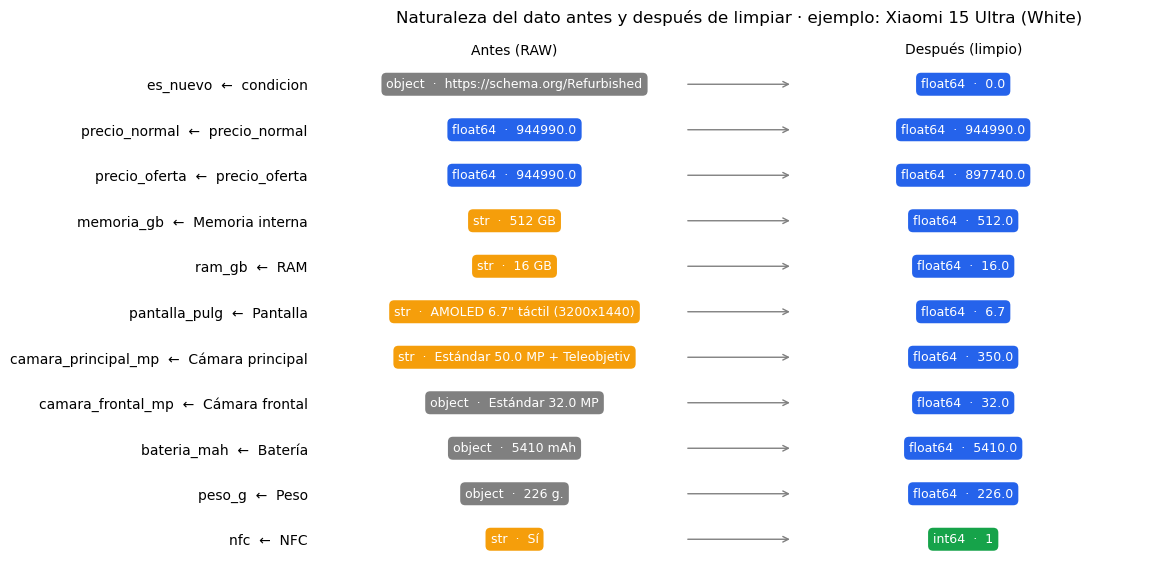

,antes,después
es_nuevo,object,float64
precio_normal,float64,float64
precio_oferta,float64,float64
memoria_gb,str,float64
ram_gb,str,float64
pantalla_pulg,str,float64
camara_principal_mp,str,float64
camara_frontal_mp,object,float64
bateria_mah,object,float64
peso_g,object,float64


In [7]:
# Naturaleza del dato: tipo de cada columna antes (RAW) y después (limpio), con un valor de ejemplo

cols = {"es_nuevo": "condicion", **origen}                              # columna limpia → columna RAW (suma "condicion")
i = clean.camara_principal_mp.idxmax()                                  # mismo equipo de ejemplo que la tabla anterior
tipo = lambda s: "str" if pd.api.types.is_string_dtype(s) else str(s.dtype)   # nombre simple del tipo de la columna
color = {"str": "#f59e0b", "float64": "#2563eb", "int64": "#16a34a"}    # naranja = texto, azul = decimal, verde = entero

fig, ax = plt.subplots(figsize=(11, 6.5))
for y, (limpia, cruda) in enumerate(cols.items()):                     # una fila del gráfico por columna
    for x, s, v in [(0, df[cruda], df.loc[i, cruda]), (1, clean[limpia], clean.loc[i, limpia])]:   # x=0 antes, x=1 después
        t = tipo(s)
        ax.text(x, y, f"{t}  ·  {str(v)[:30]}", ha="center", va="center", fontsize=9, color="white",
                bbox=dict(boxstyle="round,pad=0.4", facecolor=color.get(t, "gray"), edgecolor="none"))
    ax.annotate("", xy=(0.62, y), xytext=(0.38, y), arrowprops=dict(arrowstyle="->", color="gray"))   # flecha antes → después

ax.set_yticks(range(len(cols)), [f"{c}  ←  {r}" for c, r in cols.items()])   # columna limpia ← columna RAW
ax.set_xticks([0, 1], ["Antes (RAW)", "Después (limpio)"]); ax.xaxis.tick_top()
ax.set(xlim=(-0.45, 1.45), ylim=(len(cols) - 0.5, -0.5))
ax.set_title(f"Naturaleza del dato antes y después de limpiar · ejemplo: {df.nombre[i]}", pad=28)
for lado in ax.spines.values(): lado.set_visible(False)                 # sin marco
ax.tick_params(length=0)
plt.show()

pd.DataFrame({"antes": [tipo(df[r]) for r in cols.values()], "después": [tipo(clean[c]) for c in cols]}, index=list(cols))   # resumen en tabla

### Paso 4: Faltantes que quedan y guardado

**Justificación:**

- **Cupones vacíos:** descuento 0 (Paso 3). La tienda no tiene cupón; no es un dato perdido.

- **Ofertas con plan:** eliminadas (Paso 3). Los **10 celulares sin oferta liberada** (9 solo con plan y 1 sin ofertas) se conservan con su ficha y precio vacío. No sirven para comparar precios ni como etiqueta del modelo, pero sí para contar los modelos del mercado (pregunta c).

- **Publicaciones repetidas:** se deja una por grupo (Paso 3).

- **Características en "N/A"** (peso, batería, cámara frontal): **no se imputan aquí.** Se imputan en el notebook 04 con la **mediana de la marca** (o la general, si la marca no tiene el dato), aprendida **solo con los datos de entrenamiento** y aplicada después a validación y test. Si la mediana se calculara aquí con todos los celulares, el preprocesamiento usaría información de celulares que el modelo debe tratar como no vistos (fuga de datos).

  - Se usa la mediana de la marca porque los equipos de una marca comparten componentes, y la mediana es robusta a extremos (plegables, equipos básicos).

  - La exploración (notebook 03) usa los datos disponibles: los promedios y correlaciones de pandas ignoran los vacíos.

In [8]:
# Faltantes que quedan en la tabla limpia y por qué. Las características en "N/A" NO se imputan aquí:
# la mediana se aprende en el notebook 04 solo con los datos de entrenamiento. Si se calculara aquí, usaría también
# los celulares de validación y test, que el modelo debe tratar como no vistos.

u = clean.drop_duplicates("nombre")                                        # 1 fila por celular
motivo = {c: "Celular sin oferta liberada: sin precio de equipo" for c in ["tienda", "id_oferta", "condicion", "es_nuevo", "precio_normal", "precio_oferta"]}
faltan = pd.DataFrame({"filas con NaN": clean.isna().sum(), "celulares con NaN": u.isna().sum()})[lambda t: t["filas con NaN"] > 0]
faltan["motivo"] = [motivo.get(c, '"N/A" en el sitio: se imputa en el notebook 04') for c in faltan.index]

clean.to_csv(PROC / "data_processed.csv", index=False)                    # se guarda en data/processed
print(clean.shape, "| celulares:", len(u), "| duplicados:", clean.duplicated().sum())
print("Celulares por disponibilidad:", u.disponibilidad.value_counts().to_dict())
faltan

(1006, 17) | celulares: 242 | duplicados: 0
Celulares por disponibilidad: {'Liberado': 232, 'Solo con plan': 9, 'Sin ofertas': 1}


,filas con NaN,celulares con NaN,motivo
tienda,10,10,Celular sin oferta liberada: sin precio de equipo
id_oferta,10,10,Celular sin oferta liberada: sin precio de equipo
condicion,10,10,Celular sin oferta liberada: sin precio de equipo
es_nuevo,10,10,Celular sin oferta liberada: sin precio de equipo
precio_normal,10,10,Celular sin oferta liberada: sin precio de equipo
precio_oferta,10,10,Celular sin oferta liberada: sin precio de equipo
camara_frontal_mp,4,4,"""N/A"" en el sitio: se imputa en el notebook 04"
bateria_mah,33,10,"""N/A"" en el sitio: se imputa en el notebook 04"
peso_g,88,17,"""N/A"" en el sitio: se imputa en el notebook 04"


**Control final:** el archivo guardado debe tener **0 duplicados** y vacíos solo donde corresponde. Con la extracción del 08-11: 1.029 ofertas liberadas + 10 celulares sin oferta liberada − 33 publicaciones repetidas = **1.006 filas × 17 columnas, 242 celulares**.
- **Precio, tienda y condición vacíos:** las 10 filas de los celulares sin oferta liberada.
- **Características vacías (se imputan en el 04):** peso en 88 filas (17 celulares), batería en 33 (10) y cámara frontal en 4 (4).